# Market & User Engagement Analysis
## Google Play Store Case Study

### Objective

This project explores the Google Play Store ecosystem to identify patterns associated with app adoption, user engagement, ratings, and monetisation.

The analysis aims to understand:

- Which app categories dominate the market and attract the most installs
- How user engagement, measured through reviews, relates to ratings and adoption
- How free and paid apps differ in performance
- Whether pricing is associated with installs and ratings
- How app and audience characteristics relate to market performance

The project follows an exploratory data analysis (EDA) approach, progressing from data quality assessment and cleaning to pattern discovery, visualisation, and actionable insights.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("googleplaystore.csv")

## 1. Data Audit

Before cleaning or transforming the dataset, an initial audit is performed to understand its structure, data types, missing values, uniqueness, and potential duplication.

No observations are removed or modified at this stage.

In [4]:
print("Dataset shape:", df.shape)

display(df.head())

print("\nColumn information:")
df.info()

Dataset shape: (10841, 13)


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up



Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  object 
 5   Installs        10841 non-null  object 
 6   Type            10840 non-null  object 
 7   Price           10841 non-null  object 
 8   Content Rating  10840 non-null  object 
 9   Genres          10841 non-null  object 
 10  Last Updated    10841 non-null  object 
 11  Current Ver     10833 non-null  object 
 12  Android Ver     10838 non-null  object 
dtypes: float64(1), object(12)
memory usage: 1.1+ MB


### 1.1 Data Quality Summary

The following audit summarises the data type, missing-value count, missing-value percentage, and number of unique values for each variable.

Duplicate records and repeated app names are examined separately to identify potential data-quality issues that require further investigation.

In [6]:
audit = pd.DataFrame({
    "Data Type": df.dtypes,
    "Missing Values": df.isnull().sum(),
    "Missing %": (df.isnull().sum() / len(df) * 100).round(2),
    "Unique Values": df.nunique()
})

display(audit)

print("Fully duplicated rows:", df.duplicated().sum())
print("Unique app names:", df["App"].nunique())
print("Duplicate app-name occurrences:", df["App"].duplicated().sum())

,Data Type,Missing Values,Missing %,Unique Values
App,object,0,0.00,9660
Category,object,0,0.00,34
Rating,float64,1474,13.60,40
Reviews,object,0,0.00,6002
Size,object,0,0.00,462
Installs,object,0,0.00,22
Type,object,1,0.01,3
Price,object,0,0.00,93
Content Rating,object,1,0.01,6
Genres,object,0,0.00,120


Fully duplicated rows: 483
Unique app names: 9660
Duplicate app-name occurrences: 1181


### 1.2 Data Quality Investigation

The initial audit identified several issues requiring closer examination before cleaning:

- Missing values, particularly in `Rating`
- Exact duplicate records and repeated app names
- Numerical variables stored as text
- Potentially malformed or inconsistent values

These issues are investigated individually before deciding how they should be handled.

In [8]:
columns_to_check = [
    "Category",
    "Rating",
    "Reviews",
    "Size",
    "Installs",
    "Type",
    "Price",
    "Content Rating"
]

for column in columns_to_check:
    print(f"\n--- {column} ---")
    print(df[column].value_counts(dropna=False).head(20))


--- Category ---
Category
FAMILY                 1972
GAME                   1144
TOOLS                   843
MEDICAL                 463
BUSINESS                460
PRODUCTIVITY            424
PERSONALIZATION         392
COMMUNICATION           387
SPORTS                  384
LIFESTYLE               382
FINANCE                 366
HEALTH_AND_FITNESS      341
PHOTOGRAPHY             335
SOCIAL                  295
NEWS_AND_MAGAZINES      283
SHOPPING                260
TRAVEL_AND_LOCAL        258
DATING                  234
BOOKS_AND_REFERENCE     231
VIDEO_PLAYERS           175
Name: count, dtype: int64

--- Rating ---
Rating
NaN    1474
4.4    1109
4.3    1076
4.5    1038
4.2     952
4.6     823
4.1     708
4.0     568
4.7     499
3.9     386
3.8     303
5.0     274
3.7     239
4.8     234
3.6     174
3.5     163
3.4     128
3.3     102
4.9      87
3.0      83
Name: count, dtype: int64

--- Reviews ---
Reviews
0     596
1     272
2     214
3     175
4     137
5     108
6      97
7  

Exploratory Data Analysis (EDA)

In [10]:
# Check ratings outside the valid Google Play range of 1–5
invalid_ratings = df[(df["Rating"].notna()) & (~df["Rating"].between(1, 5))]

print("Invalid rating records:")
display(invalid_ratings)

# Inspect unexpected values in key categorical fields
print("\nUnique Type values:")
print(df["Type"].value_counts(dropna=False))

print("\nUnique Content Rating values:")
print(df["Content Rating"].value_counts(dropna=False))

# Identify unexpected categories
expected_categories = [
    "ART_AND_DESIGN", "AUTO_AND_VEHICLES", "BEAUTY", "BOOKS_AND_REFERENCE",
    "BUSINESS", "COMICS", "COMMUNICATION", "DATING", "EDUCATION",
    "ENTERTAINMENT", "EVENTS", "FINANCE", "FOOD_AND_DRINK", "HEALTH_AND_FITNESS",
    "HOUSE_AND_HOME", "LIBRARIES_AND_DEMO", "LIFESTYLE", "GAME", "FAMILY",
    "MEDICAL", "SOCIAL", "SHOPPING", "PHOTOGRAPHY", "SPORTS", "TRAVEL_AND_LOCAL",
    "TOOLS", "PERSONALIZATION", "PRODUCTIVITY", "PARENTING", "WEATHER",
    "VIDEO_PLAYERS", "NEWS_AND_MAGAZINES", "MAPS_AND_NAVIGATION"
]

unexpected_categories = df[~df["Category"].isin(expected_categories)]

print("\nUnexpected category records:")
display(unexpected_categories)

Invalid rating records:


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10472,Life Made WI-Fi Touchscreen Photo Frame,1.9,19.0,3.0M,"1,000+",Free,0,Everyone,NaN,"February 11, 2018",1.0.19,4.0 and up,NaN



Unique Type values:
Type
Free    10039
Paid      800
NaN         1
0           1
Name: count, dtype: int64

Unique Content Rating values:
Content Rating
Everyone           8714
Teen               1208
Mature 17+          499
Everyone 10+        414
Adults only 18+       3
Unrated               2
NaN                   1
Name: count, dtype: int64

Unexpected category records:


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10472,Life Made WI-Fi Touchscreen Photo Frame,1.9,19.0,3.0M,"1,000+",Free,0,Everyone,NaN,"February 11, 2018",1.0.19,4.0 and up,NaN


### 1.4 Removal of Malformed Record

Validation identified one malformed observation in which values were shifted across multiple columns. This produced impossible values such as a rating of 19 and an invalid app category.

Because the record cannot be reconstructed reliably from the available data, it is removed rather than corrected using assumptions.

In [12]:
# Remove records with invalid ratings or unexpected categories
malformed_mask = (
    ((df["Rating"].notna()) & (~df["Rating"].between(1, 5))) |
    (~df["Category"].isin(expected_categories))
)

print("Malformed records removed:", malformed_mask.sum())

df = df.loc[~malformed_mask].copy()

print("Dataset shape after removal:", df.shape)

Malformed records removed: 1
Dataset shape after removal: (10840, 13)


### 1.5 Duplicate Record Investigation

The initial audit identified both exact duplicate rows and repeated app names. These are investigated separately because repeated app names may represent identical duplicate records or different observations of the same app.

Removing all repeated app names without investigation could therefore discard legitimate information.

In [14]:
# Recalculate duplicates after removing the malformed record
print("Exact duplicate rows:", df.duplicated().sum())
print("Repeated app-name occurrences:", df["App"].duplicated().sum())

# Inspect apps appearing more than once
duplicate_apps = df[df.duplicated(subset="App", keep=False)].sort_values("App")

print("Number of apps with multiple records:",
      duplicate_apps["App"].nunique())

display(duplicate_apps.head(20))

Exact duplicate rows: 483
Repeated app-name occurrences: 1181
Number of apps with multiple records: 798


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
1393,10 Best Foods for You,HEALTH_AND_FITNESS,4.0,2490,3.8M,"500,000+",Free,0,Everyone 10+,Health & Fitness,"February 17, 2017",1.9,2.3.3 and up
1407,10 Best Foods for You,HEALTH_AND_FITNESS,4.0,2490,3.8M,"500,000+",Free,0,Everyone 10+,Health & Fitness,"February 17, 2017",1.9,2.3.3 and up
2543,1800 Contacts - Lens Store,MEDICAL,4.7,23160,26M,"1,000,000+",Free,0,Everyone,Medical,"July 27, 2018",7.4.1,5.0 and up
2322,1800 Contacts - Lens Store,MEDICAL,4.7,23160,26M,"1,000,000+",Free,0,Everyone,Medical,"July 27, 2018",7.4.1,5.0 and up
2385,2017 EMRA Antibiotic Guide,MEDICAL,4.4,12,3.8M,"1,000+",Paid,$16.99,Everyone,Medical,"January 27, 2017",1.0.5,4.0.3 and up
2256,2017 EMRA Antibiotic Guide,MEDICAL,4.4,12,3.8M,"1,000+",Paid,$16.99,Everyone,Medical,"January 27, 2017",1.0.5,4.0.3 and up
1337,21-Day Meditation Experience,HEALTH_AND_FITNESS,4.4,11506,15M,"100,000+",Free,0,Everyone,Health & Fitness,"August 2, 2018",3.0.0,4.1 and up
1434,21-Day Meditation Experience,HEALTH_AND_FITNESS,4.4,11506,15M,"100,000+",Free,0,Everyone,Health & Fitness,"August 2, 2018",3.0.0,4.1 and up
3083,365Scores - Live Scores,SPORTS,4.6,666521,25M,"10,000,000+",Free,0,Everyone,Sports,"July 29, 2018",5.5.9,4.1 and up
5415,365Scores - Live Scores,SPORTS,4.6,666246,25M,"10,000,000+",Free,0,Everyone,Sports,"July 29, 2018",5.5.9,4.1 and up


### 1.6 Distinguishing Exact Duplicates from Updated App Records

Exact duplicate rows provide no additional information and can be removed safely. However, some apps may appear multiple times with differences in attributes such as ratings, review counts, versions, or update dates.

The repeated app records are therefore examined after removing exact duplicates to determine whether the remaining repetitions represent distinct observations.

In [16]:
# Remove exact duplicate rows
rows_before = len(df)

df = df.drop_duplicates().copy()

print("Exact duplicate rows removed:", rows_before - len(df))
print("Dataset shape after removing exact duplicates:", df.shape)

# Reassess repeated app names
repeated_after_exact = df[df.duplicated(subset="App", keep=False)].sort_values("App")

print("Repeated app-name occurrences remaining:",
      df["App"].duplicated().sum())

print("Apps still having multiple records:",
      repeated_after_exact["App"].nunique())

display(repeated_after_exact.head(20))

Exact duplicate rows removed: 483
Dataset shape after removing exact duplicates: (10357, 13)
Repeated app-name occurrences remaining: 698
Apps still having multiple records: 523


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
5415,365Scores - Live Scores,SPORTS,4.6,666246,25M,"10,000,000+",Free,0,Everyone,Sports,"July 29, 2018",5.5.9,4.1 and up
3083,365Scores - Live Scores,SPORTS,4.6,666521,25M,"10,000,000+",Free,0,Everyone,Sports,"July 29, 2018",5.5.9,4.1 and up
1755,8 Ball Pool,GAME,4.5,14200344,52M,"100,000,000+",Free,0,Everyone,Sports,"July 31, 2018",4.0.0,4.0.3 and up
1703,8 Ball Pool,GAME,4.5,14198602,52M,"100,000,000+",Free,0,Everyone,Sports,"July 31, 2018",4.0.0,4.0.3 and up
1871,8 Ball Pool,GAME,4.5,14201891,52M,"100,000,000+",Free,0,Everyone,Sports,"July 31, 2018",4.0.0,4.0.3 and up
1844,8 Ball Pool,GAME,4.5,14200550,52M,"100,000,000+",Free,0,Everyone,Sports,"July 31, 2018",4.0.0,4.0.3 and up
1675,8 Ball Pool,GAME,4.5,14198297,52M,"100,000,000+",Free,0,Everyone,Sports,"July 31, 2018",4.0.0,4.0.3 and up
1970,8 Ball Pool,GAME,4.5,14201604,52M,"100,000,000+",Free,0,Everyone,Sports,"July 31, 2018",4.0.0,4.0.3 and up
3953,8 Ball Pool,SPORTS,4.5,14184910,52M,"100,000,000+",Free,0,Everyone,Sports,"July 31, 2018",4.0.0,4.0.3 and up
559,95Live -SG#1 Live Streaming App,DATING,4.1,4953,15M,"1,000,000+",Free,0,Teen,Dating,"August 1, 2018",8.7.2,4.2 and up


### 1.7 Analysis of Repeated App Records

After removing exact duplicates, some app names still occur more than once. These records may reflect updated observations of the same app rather than duplicate data.

To determine an appropriate deduplication strategy, the remaining repeated records are compared across key attributes, including ratings, reviews, installs, versions, and update dates.

In [18]:
# Identify columns that vary within repeated app records
comparison_cols = [
    "Rating", "Reviews", "Size", "Installs",
    "Type", "Price", "Content Rating",
    "Last Updated", "Current Ver", "Android Ver"
]

variation_summary = {}

for col in comparison_cols:
    variation_summary[col] = (
        repeated_after_exact.groupby("App")[col]
        .nunique(dropna=False)
        .gt(1)
        .sum()
    )

variation_summary = pd.Series(
    variation_summary,
    name="Apps with differing values"
).sort_values(ascending=False)

display(variation_summary)

# Show examples where the same app has genuinely different records
apps_with_variation = (
    repeated_after_exact.groupby("App")[comparison_cols]
    .nunique(dropna=False)
    .gt(1)
    .any(axis=1)
)

varying_app_names = apps_with_variation[apps_with_variation].index

print("Apps with genuinely different repeated records:",
      len(varying_app_names))

display(
    repeated_after_exact[
        repeated_after_exact["App"].isin(varying_app_names)
    ].head(20)
)

Reviews           517
Last Updated       42
Current Ver        24
Rating             18
Size               17
Installs           15
Android Ver        14
Type                2
Price               2
Content Rating      0
Name: Apps with differing values, dtype: int64

Apps with genuinely different repeated records: 519


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
5415,365Scores - Live Scores,SPORTS,4.6,666246,25M,"10,000,000+",Free,0,Everyone,Sports,"July 29, 2018",5.5.9,4.1 and up
3083,365Scores - Live Scores,SPORTS,4.6,666521,25M,"10,000,000+",Free,0,Everyone,Sports,"July 29, 2018",5.5.9,4.1 and up
1755,8 Ball Pool,GAME,4.5,14200344,52M,"100,000,000+",Free,0,Everyone,Sports,"July 31, 2018",4.0.0,4.0.3 and up
1703,8 Ball Pool,GAME,4.5,14198602,52M,"100,000,000+",Free,0,Everyone,Sports,"July 31, 2018",4.0.0,4.0.3 and up
1871,8 Ball Pool,GAME,4.5,14201891,52M,"100,000,000+",Free,0,Everyone,Sports,"July 31, 2018",4.0.0,4.0.3 and up
1844,8 Ball Pool,GAME,4.5,14200550,52M,"100,000,000+",Free,0,Everyone,Sports,"July 31, 2018",4.0.0,4.0.3 and up
1675,8 Ball Pool,GAME,4.5,14198297,52M,"100,000,000+",Free,0,Everyone,Sports,"July 31, 2018",4.0.0,4.0.3 and up
1970,8 Ball Pool,GAME,4.5,14201604,52M,"100,000,000+",Free,0,Everyone,Sports,"July 31, 2018",4.0.0,4.0.3 and up
3953,8 Ball Pool,SPORTS,4.5,14184910,52M,"100,000,000+",Free,0,Everyone,Sports,"July 31, 2018",4.0.0,4.0.3 and up
559,95Live -SG#1 Live Streaming App,DATING,4.1,4953,15M,"1,000,000+",Free,0,Teen,Dating,"August 1, 2018",8.7.2,4.2 and up


### 1.8 App-Level Deduplication

After exact duplicates were removed, repeated app records were compared across key attributes. Most variation occurred in review counts, while comparatively few records differed in update date or version information. This indicates that the repeated observations cannot reliably be treated as chronological snapshots.

Because the analysis is conducted at the app level, retaining multiple observations for the same app could disproportionately weight frequently repeated apps. One record is therefore retained per app.

Where multiple records exist, the observation with the highest review count is retained. Since review counts are cumulative, this provides a consistent rule for selecting the record containing the greatest observed level of user engagement.

In [20]:
# Check whether all review values can be interpreted as integers
review_numeric = pd.to_numeric(df["Reviews"], errors="coerce")

print("Non-numeric review values:", review_numeric.isna().sum())

display(
    df.loc[
        review_numeric.isna(),
        ["App", "Reviews"]
    ]
)

Non-numeric review values: 0


,App,Reviews


In [21]:
# Convert Reviews to numeric
df["Reviews"] = pd.to_numeric(df["Reviews"])

rows_before = len(df)

# Retain the record with the highest review count for each app
df = (
    df.sort_values("Reviews", ascending=False)
      .drop_duplicates(subset="App", keep="first")
      .copy()
)

print("Repeated app records removed:", rows_before - len(df))
print("Final number of unique apps:", df["App"].nunique())
print("Dataset shape:", df.shape)
print("Remaining duplicate app names:", df["App"].duplicated().sum())

Repeated app records removed: 698
Final number of unique apps: 9659
Dataset shape: (9659, 13)
Remaining duplicate app names: 0


In [22]:
# Verify app-level deduplication
assert df["App"].is_unique

print("App names are unique:", df["App"].is_unique)

App names are unique: True


### 1.9 Missing Value Investigation

Following deduplication, missing values are reassessed because the number and distribution of missing observations may have changed.

Particular attention is given to `Rating`, as it is a key measure of user response and contained substantial missingness in the original dataset. Before deciding whether to remove or retain unrated apps, their characteristics are compared with rated apps.

In [24]:
missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing %": (df.isnull().sum() / len(df) * 100).round(2)
})

display(
    missing_summary[missing_summary["Missing Values"] > 0]
    .sort_values("Missing Values", ascending=False)
)

,Missing Values,Missing %
Rating,1463,15.15
Current Ver,8,0.08
Android Ver,2,0.02
Type,1,0.01


In [25]:
rated = df[df["Rating"].notna()]
unrated = df[df["Rating"].isna()]

print("Rated apps:", len(rated))
print("Unrated apps:", len(unrated))
print("Percentage unrated:", round(len(unrated) / len(df) * 100, 2), "%")

rating_comparison = pd.DataFrame({
    "Rated Apps": [
        rated["Reviews"].median(),
        rated["Reviews"].mean()
    ],
    "Unrated Apps": [
        unrated["Reviews"].median(),
        unrated["Reviews"].mean()
    ]
}, index=["Median Reviews", "Mean Reviews"])

display(rating_comparison)

print("\nMost common categories among unrated apps:")
display(unrated["Category"].value_counts().head(10))

Rated apps: 8196
Unrated apps: 1463
Percentage unrated: 15.15 %


,Rated Apps,Unrated Apps
Median Reviews,3017.000000,1.00000
Mean Reviews,255500.778184,18.12987



Most common categories among unrated apps:


Category
FAMILY                 225
BUSINESS               157
TOOLS                  109
MEDICAL                105
PERSONALIZATION         78
PRODUCTIVITY            73
LIFESTYLE               68
SPORTS                  65
COMMUNICATION           59
BOOKS_AND_REFERENCE     53
Name: count, dtype: int64

### 1.10 Verification of Rating Completeness

Following app-level deduplication, no missing ratings remained. Because the original dataset contained substantial missingness in `Rating`, this unexpected change is verified against the raw data to determine whether unrated observations belonged to apps that also appeared elsewhere with valid ratings.

In [27]:
raw_check = pd.read_csv("googleplaystore.csv")

missing_rating_apps = raw_check.loc[
    raw_check["Rating"].isna(), "App"
]

print("Raw records with missing Rating:", raw_check["Rating"].isna().sum())
print("Unique apps among missing-Rating records:", missing_rating_apps.nunique())

# Check whether those app names have another record with a valid rating
valid_rating_apps = set(
    raw_check.loc[raw_check["Rating"].notna(), "App"]
)

missing_apps_with_valid_record = missing_rating_apps.isin(valid_rating_apps)

print(
    "Missing-rating records whose app also has a valid-rating record:",
    missing_apps_with_valid_record.sum()
)

print(
    "Unique apps with no valid rating anywhere:",
    missing_rating_apps[
        ~missing_rating_apps.isin(valid_rating_apps)
    ].nunique()
)

Raw records with missing Rating: 1474
Unique apps among missing-Rating records: 1464
Missing-rating records whose app also has a valid-rating record: 1
Unique apps with no valid rating anywhere: 1463


In [28]:
print("Current dataframe rows:", len(df))
print("Current unique apps:", df["App"].nunique())
print("Current missing ratings:", df["Rating"].isna().sum())

print("\nRaw dataframe rows:", len(raw_check))
print("Raw unique apps:", raw_check["App"].nunique())
print("Raw missing ratings:", raw_check["Rating"].isna().sum())

Current dataframe rows: 9659
Current unique apps: 9659
Current missing ratings: 1463

Raw dataframe rows: 10841
Raw unique apps: 9660
Raw missing ratings: 1474


### 1.11 Reconstruction of the Cleaned Dataset

Following validation of the cleaning decisions, the dataset is reconstructed from the raw source to ensure that all transformations are applied consistently and that unrated apps are preserved.

The established cleaning rules are applied sequentially: removal of the malformed record, removal of exact duplicates, conversion of review counts to numeric format, and app-level deduplication using the highest observed review count.

In [30]:
# Reload raw data
df = pd.read_csv("googleplaystore.csv")

# 1. Remove malformed record
malformed_mask = (
    ((df["Rating"].notna()) & (~df["Rating"].between(1, 5))) |
    (~df["Category"].isin(expected_categories))
)

df = df.loc[~malformed_mask].copy()

# 2. Remove exact duplicate rows
df = df.drop_duplicates().copy()

# 3. Convert Reviews to numeric
df["Reviews"] = pd.to_numeric(df["Reviews"])

# 4. Retain one observation per app:
#    highest observed review count
df = (
    df.sort_values("Reviews", ascending=False)
      .drop_duplicates(subset="App", keep="first")
      .copy()
)

# Verification
print("Rows:", len(df))
print("Unique apps:", df["App"].nunique())
print("Duplicate app names:", df["App"].duplicated().sum())
print("Missing ratings:", df["Rating"].isna().sum())
print("Missing rating %:", round(df["Rating"].isna().mean() * 100, 2))

Rows: 9659
Unique apps: 9659
Duplicate app names: 0
Missing ratings: 1463
Missing rating %: 15.15


### 1.12 Missing Rating Strategy

After reconstruction, 1,463 of the 9,659 unique apps (15.15%) have no recorded rating.

These missing ratings are retained rather than imputed because the absence of a rating represents a meaningful lack of observed user feedback rather than an unknown numerical value that can be estimated reliably.

Unrated apps are therefore included in market-level analyses such as category, pricing, and installation patterns, but excluded from analyses that directly require a rating value.

In [32]:
missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing %": (df.isnull().sum() / len(df) * 100).round(2)
})

display(
    missing_summary[missing_summary["Missing Values"] > 0]
    .sort_values("Missing Values", ascending=False)
)

,Missing Values,Missing %
Rating,1463,15.15
Current Ver,8,0.08
Android Ver,2,0.02
Type,1,0.01


### 1.13 Remaining Missing Values

Apart from `Rating`, only a small number of missing values remain in the version-related fields `Current Ver` and `Android Ver`.

Because these variables are not central to the primary analytical questions and their missingness is minimal, the observations are retained without imputation. Missing version information does not prevent these apps from contributing to the market, engagement, pricing, or installation analyses.

## 2. Data Preparation

Several variables are stored as text because their raw values contain symbols, units, or formatting characters. These fields are transformed into analysis-ready formats while preserving their original meaning.

The main transformations involve:

- Converting installation counts to numeric values
- Converting prices to numeric values
- Standardising app size into a common unit
- Converting update dates to datetime format
- Validating the resulting numerical ranges

In [35]:
format_check = pd.DataFrame({
    "Column": ["Installs", "Price", "Size", "Last Updated"],
    "Data Type": [
        df["Installs"].dtype,
        df["Price"].dtype,
        df["Size"].dtype,
        df["Last Updated"].dtype
    ],
    "Example Values": [
        list(df["Installs"].dropna().unique()[:10]),
        list(df["Price"].dropna().unique()[:10]),
        list(df["Size"].dropna().unique()[:10]),
        list(df["Last Updated"].dropna().unique()[:10])
    ]
})

display(format_check)

,Column,Data Type,Example Values
0,Installs,object,"[1,000,000,000+, 100,000,000+, 500,000,000+, 5..."
1,Price,object,"[0, $6.99, $0.99, $2.99, $1.99, $2.49, $4.99, ..."
2,Size,object,"[Varies with device, 98M, 76M, 97M, 74M, 40M, ..."
3,Last Updated,object,"[August 3, 2018, July 31, 2018, August 1, 2018..."


### 2.1 Installation Count Preparation

`Installs` is stored as text because values contain commas and a trailing `+` symbol. These formatting characters are removed to create a numerical installation-threshold variable.

The resulting values should be interpreted as minimum reported installation counts rather than exact totals. For example, `1,000,000+` indicates at least one million installs.

In [37]:
# Preserve the original installation bands
df["Installs_Band"] = df["Installs"]

# Convert installation thresholds to numeric values
df["Installs"] = (
    df["Installs"]
    .str.replace(",", "", regex=False)
    .str.replace("+", "", regex=False)
    .astype(int)
)

print("Installs data type:", df["Installs"].dtype)
print("Minimum installs:", df["Installs"].min())
print("Maximum installs:", df["Installs"].max())

display(
    df[["App", "Installs_Band", "Installs"]].head(10)
)

Installs data type: int64
Minimum installs: 0
Maximum installs: 1000000000


,App,Installs_Band,Installs
2544,Facebook,"1,000,000,000+",1000000000
336,WhatsApp Messenger,"1,000,000,000+",1000000000
2604,Instagram,"1,000,000,000+",1000000000
382,Messenger – Text and Video Chat for Free,"1,000,000,000+",1000000000
1879,Clash of Clans,"100,000,000+",100000000
4005,Clean Master- Space Cleaner & Antivirus,"500,000,000+",500000000
1872,Subway Surfers,"1,000,000,000+",1000000000
3665,YouTube,"1,000,000,000+",1000000000
7536,"Security Master - Antivirus, VPN, AppLock, Boo...","500,000,000+",500000000
1878,Clash Royale,"100,000,000+",100000000


### 2.2 Price Preparation

`Price` is stored as text because paid-app prices include a dollar sign, while free apps are represented as zero.

The currency symbol is removed and the field is converted to a numerical variable so that pricing patterns can be analysed. The existing `Type` variable is retained to distinguish free and paid apps.

In [39]:
# Convert Price from formatted text to numeric USD values
df["Price"] = (
    df["Price"]
    .str.replace("$", "", regex=False)
    .astype(float)
)

print("Price data type:", df["Price"].dtype)
print("Minimum price: $", df["Price"].min())
print("Maximum price: $", df["Price"].max())

print("\nFree vs paid apps:")
display(df["Type"].value_counts(dropna=False))

print("\nPrice summary for paid apps:")
display(df.loc[df["Price"] > 0, "Price"].describe())

Price data type: float64
Minimum price: $ 0.0
Maximum price: $ 400.0

Free vs paid apps:


Type
Free    8904
Paid     754
NaN        1
Name: count, dtype: int64


Price summary for paid apps:


count    754.000000
mean      14.055902
std       58.821000
min        0.990000
25%        1.490000
50%        2.990000
75%        4.990000
max      400.000000
Name: Price, dtype: float64

### 2.3 App Size Preparation

`Size` contains values reported in both megabytes (`M`) and kilobytes (`k`), alongside `Varies with device` for apps without a fixed reported size.

To enable consistent analysis, measurable sizes are converted to megabytes. `Varies with device` is treated as missing for size-specific analyses rather than imputed, because no reliable numerical size can be inferred from this label.

In [41]:
def convert_size_to_mb(value):
    if value == "Varies with device":
        return np.nan
    elif value.endswith("M"):
        return float(value[:-1])
    elif value.endswith("k"):
        return float(value[:-1]) / 1024
    else:
        return np.nan

df["Size_MB"] = df["Size"].apply(convert_size_to_mb)

print("Apps with measurable size:", df["Size_MB"].notna().sum())
print("Apps with unavailable/variable size:", df["Size_MB"].isna().sum())

print("\nSize summary (MB):")
display(df["Size_MB"].describe())

display(
    df[["App", "Size", "Size_MB"]].head(15)
)

Apps with measurable size: 8431
Apps with unavailable/variable size: 1228

Size summary (MB):


count    8431.000000
mean       20.398075
std        21.828959
min         0.008301
25%         4.600000
50%        12.000000
75%        28.000000
max       100.000000
Name: Size_MB, dtype: float64

,App,Size,Size_MB
2544,Facebook,Varies with device,NaN
336,WhatsApp Messenger,Varies with device,NaN
2604,Instagram,Varies with device,NaN
382,Messenger – Text and Video Chat for Free,Varies with device,NaN
1879,Clash of Clans,98M,98.0
4005,Clean Master- Space Cleaner & Antivirus,Varies with device,NaN
1872,Subway Surfers,76M,76.0
3665,YouTube,Varies with device,NaN
7536,"Security Master - Antivirus, VPN, AppLock, Boo...",Varies with device,NaN
1878,Clash Royale,97M,97.0


### 2.4 Update Date Preparation

`Last Updated` is stored as text and is converted to a datetime variable. This enables temporal analysis of app updates and allows update recency to be compared with measures such as ratings, reviews, and installs.

In [43]:
# Convert Last Updated to datetime
df["Last Updated"] = pd.to_datetime(
    df["Last Updated"],
    errors="coerce"
)

print("Last Updated data type:", df["Last Updated"].dtype)
print("Missing dates after conversion:", df["Last Updated"].isna().sum())
print("Earliest update:", df["Last Updated"].min())
print("Latest update:", df["Last Updated"].max())

display(
    df[["App", "Last Updated"]].head(10)
)

Last Updated data type: datetime64[ns]
Missing dates after conversion: 0
Earliest update: 2010-05-21 00:00:00
Latest update: 2018-08-08 00:00:00


,App,Last Updated
2544,Facebook,2018-08-03
336,WhatsApp Messenger,2018-08-03
2604,Instagram,2018-07-31
382,Messenger – Text and Video Chat for Free,2018-08-01
1879,Clash of Clans,2018-07-15
4005,Clean Master- Space Cleaner & Antivirus,2018-08-03
1872,Subway Surfers,2018-07-12
3665,YouTube,2018-08-02
7536,"Security Master - Antivirus, VPN, AppLock, Boo...",2018-08-04
1878,Clash Royale,2018-06-27


### 2.5 Data Preparation Validation

Following the transformations, the prepared dataset is validated to confirm that key analytical variables have appropriate data types and plausible ranges before exploratory analysis begins.

In [45]:
validation = pd.DataFrame({
    "Data Type": df[
        ["Rating", "Reviews", "Installs", "Price", "Size_MB", "Last Updated"]
    ].dtypes,
    "Missing Values": df[
        ["Rating", "Reviews", "Installs", "Price", "Size_MB", "Last Updated"]
    ].isnull().sum()
})

display(validation)

print("Dataset shape:", df.shape)
print("Unique apps:", df["App"].nunique())

print("\nNumerical ranges:")
display(
    df[["Rating", "Reviews", "Installs", "Price", "Size_MB"]]
    .describe()
    .T
)

,Data Type,Missing Values
Rating,float64,1463
Reviews,int64,0
Installs,int64,0
Price,float64,0
Size_MB,float64,1228
Last Updated,datetime64[ns],0


Dataset shape: (9659, 15)
Unique apps: 9659

Numerical ranges:


,count,mean,std,min,25%,50%,75%,max
Rating,8196.0,4.173267e+00,5.362529e-01,1.000000,4.0,4.3,4.5,5.000000e+00
Reviews,9659.0,2.168041e+05,1.831430e+06,0.000000,25.0,969.0,29453.5,7.815831e+07
Installs,9659.0,7.798170e+06,5.376973e+07,0.000000,1000.0,100000.0,1000000.0,1.000000e+09
Price,9659.0,1.097231e+00,1.685162e+01,0.000000,0.0,0.0,0.0,4.000000e+02
Size_MB,8431.0,2.039807e+01,2.182896e+01,0.008301,4.6,12.0,28.0,1.000000e+02


### 2.6 Extreme Value Investigation

Large differences in app popularity and pricing can produce highly skewed numerical distributions. Extreme values are therefore investigated before exploratory analysis rather than automatically removed as outliers.

This distinction is important because exceptionally popular or expensive apps may represent genuine market behaviour and could provide useful analytical insights.

In [47]:
# Examine highest values in key numerical variables

print("Highest-priced apps:")
display(
    df.nlargest(10, "Price")[
        ["App", "Category", "Type", "Price", "Installs", "Reviews", "Rating"]
    ]
)

print("\nMost-reviewed apps:")
display(
    df.nlargest(10, "Reviews")[
        ["App", "Category", "Reviews", "Installs", "Rating"]
    ]
)

print("\nHighest installation thresholds:")
display(
    df.nlargest(10, "Installs")[
        ["App", "Category", "Installs", "Reviews", "Rating"]
    ]
)

print("\nLargest apps by reported size:")
display(
    df.nlargest(10, "Size_MB")[
        ["App", "Category", "Size_MB", "Installs", "Rating"]
    ]
)

Highest-priced apps:


,App,Category,Type,Price,Installs,Reviews,Rating
4367,I'm Rich - Trump Edition,LIFESTYLE,Paid,400.00,10000,275,3.6
5351,I am rich,LIFESTYLE,Paid,399.99,100000,3547,3.8
5356,I Am Rich Premium,FINANCE,Paid,399.99,50000,1867,4.1
5354,I am Rich Plus,FAMILY,Paid,399.99,10000,856,4.0
4362,💎 I'm rich,LIFESTYLE,Paid,399.99,10000,718,3.8
5359,I am rich(premium),FINANCE,Paid,399.99,5000,472,3.5
5362,I Am Rich Pro,FAMILY,Paid,399.99,5000,201,4.4
5369,I am Rich,FINANCE,Paid,399.99,5000,180,4.3
5364,I am rich (Most expensive app),FINANCE,Paid,399.99,1000,129,4.1
5358,I am Rich!,FINANCE,Paid,399.99,1000,93,3.8



Most-reviewed apps:


,App,Category,Reviews,Installs,Rating
2544,Facebook,SOCIAL,78158306,1000000000,4.1
336,WhatsApp Messenger,COMMUNICATION,69119316,1000000000,4.4
2604,Instagram,SOCIAL,66577446,1000000000,4.5
382,Messenger – Text and Video Chat for Free,COMMUNICATION,56646578,1000000000,4.0
1879,Clash of Clans,GAME,44893888,100000000,4.6
4005,Clean Master- Space Cleaner & Antivirus,TOOLS,42916526,500000000,4.7
1872,Subway Surfers,GAME,27725352,1000000000,4.5
3665,YouTube,VIDEO_PLAYERS,25655305,1000000000,4.3
7536,"Security Master - Antivirus, VPN, AppLock, Boo...",TOOLS,24900999,500000000,4.7
1878,Clash Royale,GAME,23136735,100000000,4.6



Highest installation thresholds:


,App,Category,Installs,Reviews,Rating
2544,Facebook,SOCIAL,1000000000,78158306,4.1
336,WhatsApp Messenger,COMMUNICATION,1000000000,69119316,4.4
2604,Instagram,SOCIAL,1000000000,66577446,4.5
382,Messenger – Text and Video Chat for Free,COMMUNICATION,1000000000,56646578,4.0
1872,Subway Surfers,GAME,1000000000,27725352,4.5
3665,YouTube,VIDEO_PLAYERS,1000000000,25655305,4.3
2884,Google Photos,PHOTOGRAPHY,1000000000,10859051,4.5
391,Skype - free IM & video calls,COMMUNICATION,1000000000,10484169,4.1
411,Google Chrome: Fast & Secure,COMMUNICATION,1000000000,9643041,4.3
3223,Maps - Navigate & Explore,TRAVEL_AND_LOCAL,1000000000,9235373,4.3



Largest apps by reported size:


,App,Category,Size_MB,Installs,Rating
1988,Hungry Shark Evolution,GAME,100.0,100000000,4.5
7404,SimCity BuildIt,FAMILY,100.0,50000000,4.5
1793,Mini Golf King - Multiplayer Game,GAME,100.0,5000000,4.5
5862,Miami crime simulator,GAME,100.0,10000000,4.0
5427,Ultimate Tennis,SPORTS,100.0,10000000,4.3
8847,Draft Simulator for FUT 18,SPORTS,100.0,5000000,4.6
1565,Talking Babsy Baby: Baby Games,LIFESTYLE,100.0,10000000,4.0
5865,Gangster Town: Vice District,FAMILY,100.0,10000000,4.3
1080,Post Bank,FINANCE,100.0,1000000,4.5
9170,Stickman Legends: Shadow Wars,GAME,100.0,1000000,4.4


### 2.7 Analysis-Ready Variables

Additional variables required for exploratory and statistical analysis are derived from the cleaned dataset. Log transformations are created for the highly skewed installation and review measures, while update dates are converted to a consistent datetime format for recency analysis.

In [169]:
# Log-transformed engagement measures
df["Log_Installs"] = np.log1p(df["Installs"])
df["Log_Reviews"] = np.log1p(df["Reviews"])

# Convert update date for recency analysis
df["Last Updated"] = pd.to_datetime(
    df["Last Updated"],
    errors="coerce"
)

print("Analysis-ready variables created successfully.")

Analysis-ready variables created successfully.


## 3. Exploratory Data Analysis

With the dataset prepared, the analysis now focuses on identifying patterns in the Google Play Store market and translating them into meaningful insights.

The exploration is organised around five analytical themes:

1. Market landscape and category performance
2. User engagement and ratings
3. Free versus paid app performance
4. Pricing and monetisation
5. App and audience characteristics

### 3.1 Market Landscape and Category Performance

The first stage examines how apps are distributed across categories and whether categories containing the largest number of apps also attract the greatest levels of user adoption.

Both app count and installation activity are considered to distinguish market supply from observed demand.

In [52]:
category_summary = (
    df.groupby("Category")
      .agg(
          App_Count=("App", "count"),
          Total_Installs=("Installs", "sum"),
          Median_Installs=("Installs", "median")
      )
      .sort_values("App_Count", ascending=False)
)

display(category_summary)

,App_Count,Total_Installs,Median_Installs
Category,,,
FAMILY,1878,6237542505,50000.0
GAME,945,13447924415,1000000.0
TOOLS,829,8102771915,50000.0
BUSINESS,420,697164865,1000.0
MEDICAL,395,38293077,1000.0
PERSONALIZATION,376,1532494782,10000.0
PRODUCTIVITY,374,5793091369,100000.0
LIFESTYLE,369,503823539,10000.0
FINANCE,345,455348734,10000.0


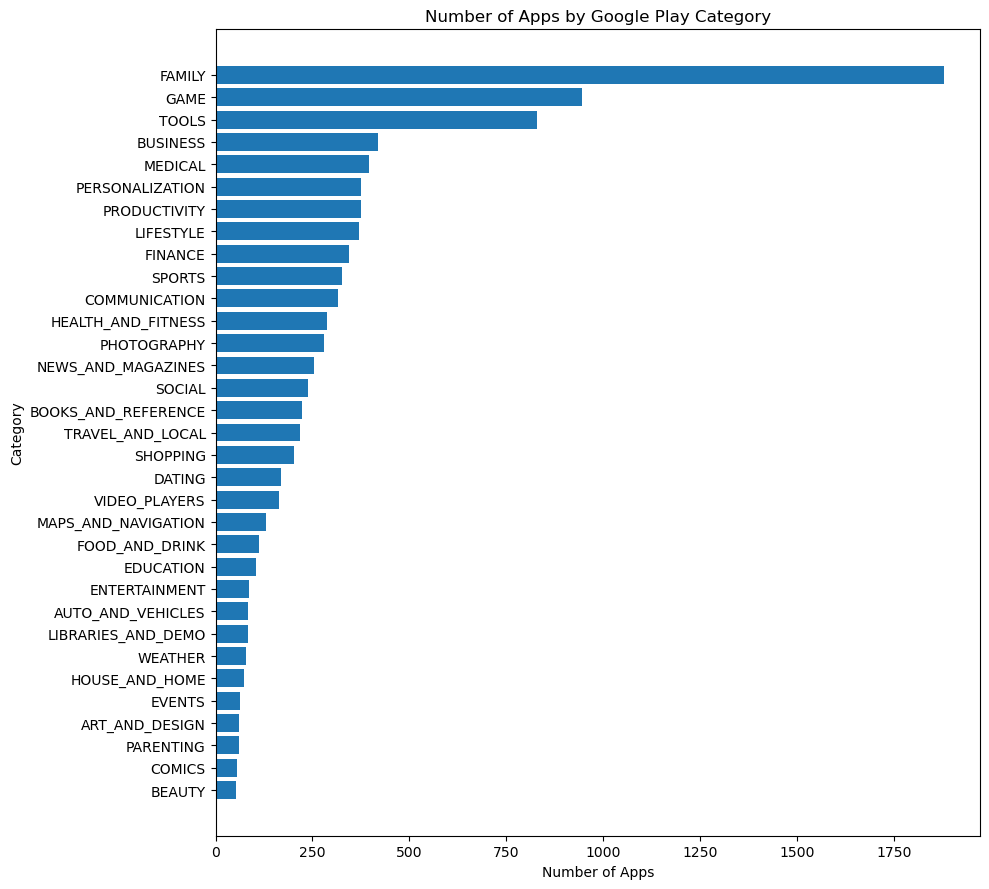

In [53]:
category_counts = category_summary["App_Count"].sort_values(ascending=True)

plt.figure(figsize=(10, 9))
plt.barh(category_counts.index, category_counts.values)

plt.title("Number of Apps by Google Play Category")
plt.xlabel("Number of Apps")
plt.ylabel("Category")

plt.tight_layout()
plt.show()

#### Category Adoption

App count alone indicates how crowded a category is but does not show how strongly users adopt apps within that category.

Category performance is therefore compared using both total reported installation thresholds and median installations per app. The median provides additional context by reducing the influence of a small number of exceptionally popular apps.

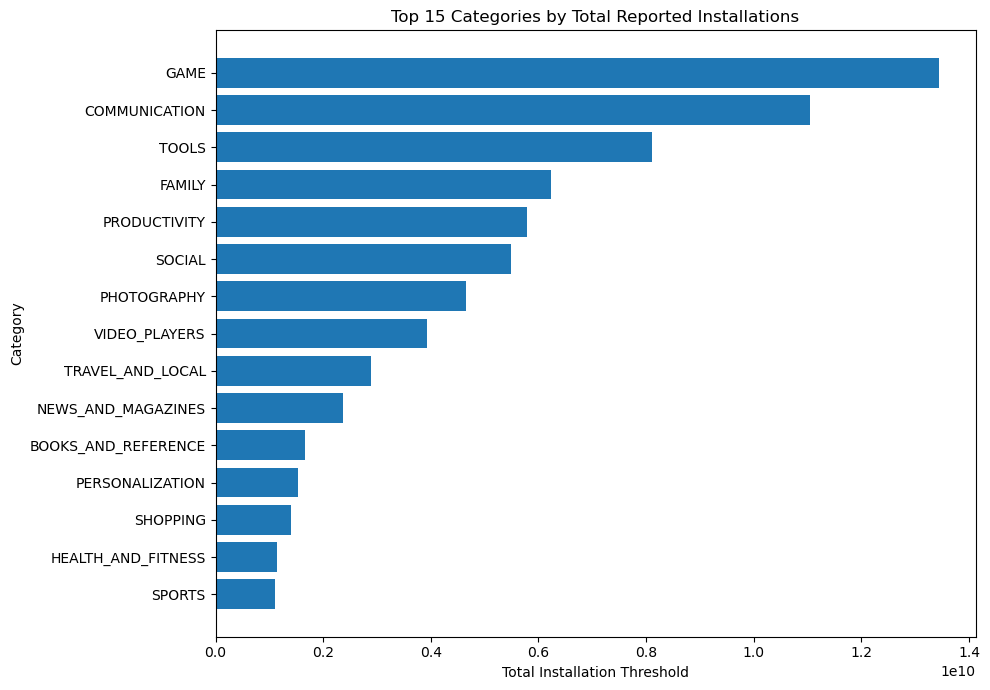

In [55]:
top_total_installs = (
    category_summary["Total_Installs"]
    .sort_values(ascending=False)
    .head(15)
    .sort_values()
)

plt.figure(figsize=(10, 7))
plt.barh(top_total_installs.index, top_total_installs.values)

plt.title("Top 15 Categories by Total Reported Installations")
plt.xlabel("Total Installation Threshold")
plt.ylabel("Category")

plt.tight_layout()
plt.show()

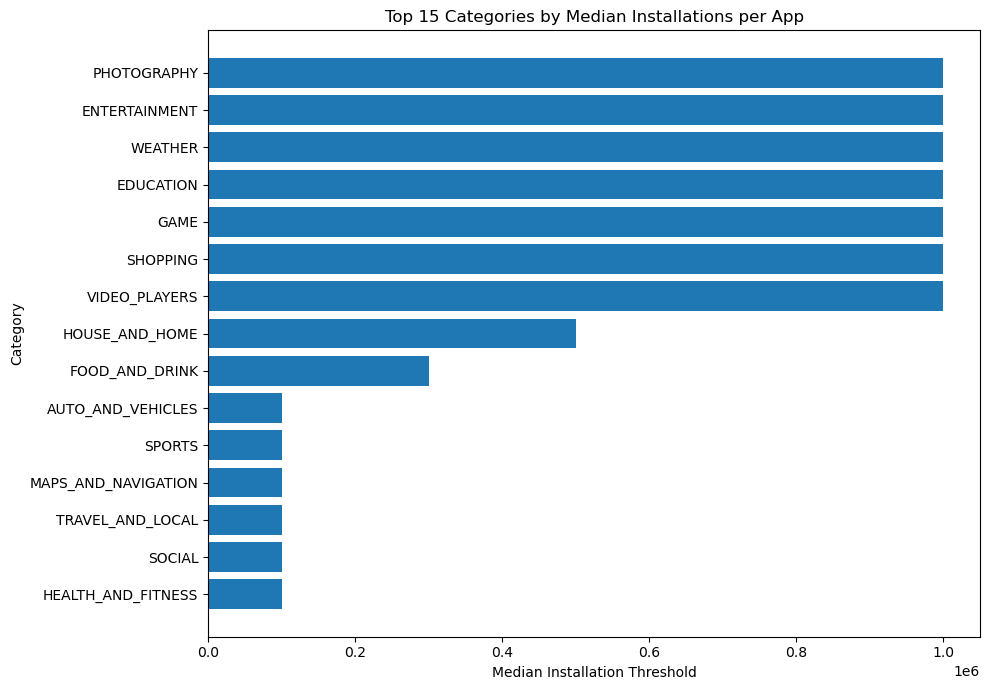

In [56]:
top_median_installs = (
    category_summary["Median_Installs"]
    .sort_values(ascending=False)
    .head(15)
    .sort_values()
)

plt.figure(figsize=(10, 7))
plt.barh(top_median_installs.index, top_median_installs.values)

plt.title("Top 15 Categories by Median Installations per App")
plt.xlabel("Median Installation Threshold")
plt.ylabel("Category")

plt.tight_layout()
plt.show()

In [57]:
market_comparison = (
    category_summary
    .assign(
        App_Count_Rank=lambda x: x["App_Count"].rank(
            ascending=False, method="min"
        ),
        Total_Installs_Rank=lambda x: x["Total_Installs"].rank(
            ascending=False, method="min"
        ),
        Median_Installs_Rank=lambda x: x["Median_Installs"].rank(
            ascending=False, method="min"
        )
    )
    .sort_values("App_Count_Rank")
)

display(
    market_comparison[
        [
            "App_Count",
            "App_Count_Rank",
            "Total_Installs",
            "Total_Installs_Rank",
            "Median_Installs",
            "Median_Installs_Rank"
        ]
    ]
)

,App_Count,App_Count_Rank,Total_Installs,Total_Installs_Rank,Median_Installs,Median_Installs_Rank
Category,,,,,,
FAMILY,1878,1.0,6237542505,4.0,50000.0,21.0
GAME,945,2.0,13447924415,1.0,1000000.0,1.0
TOOLS,829,3.0,8102771915,3.0,50000.0,21.0
BUSINESS,420,4.0,697164865,17.0,1000.0,31.0
MEDICAL,395,5.0,38293077,30.0,1000.0,31.0
PERSONALIZATION,376,6.0,1532494782,12.0,10000.0,25.0
PRODUCTIVITY,374,7.0,5793091369,5.0,100000.0,10.0
LIFESTYLE,369,8.0,503823539,18.0,10000.0,25.0
FINANCE,345,9.0,455348734,20.0,10000.0,25.0


#### Insight: Market Supply Does Not Correspond Directly to User Adoption

The category comparison reveals a substantial mismatch between app supply and user adoption.

`FAMILY` is the most crowded category with 1,878 apps, yet ranks only fourth in total reported installations and has a median installation threshold of 50,000. In contrast, `GAME` contains roughly half as many apps (945) but ranks first in both total installations and median installations, with the typical app reaching the 1,000,000+ installation band.

A similar pattern appears in categories such as `PHOTOGRAPHY`, `SHOPPING`, and `ENTERTAINMENT`, which contain considerably fewer apps but achieve median installation thresholds of 1,000,000.

Conversely, `BUSINESS` and `MEDICAL` rank fourth and fifth in app supply but have median installation thresholds of only 1,000, placing them among the lowest categories for typical adoption.

Overall, category size alone is a poor indicator of user demand. Some highly populated categories appear fragmented across many relatively low-adoption apps, while several smaller categories show substantially stronger adoption per app.

### 3.2 User Engagement and Ratings

Ratings are commonly interpreted as indicators of app quality, but high user satisfaction does not necessarily imply high market adoption.

This section examines the relationship between ratings, review activity, and installation levels to determine whether highly rated apps also tend to attract larger audiences.

In [60]:
engagement_summary = df[["Rating", "Reviews", "Installs"]].describe().T
display(engagement_summary)

rated_df = df[df["Rating"].notna()].copy()

print("Rated apps:", len(rated_df))
print("Median rating:", rated_df["Rating"].median())
print("Mean rating:", round(rated_df["Rating"].mean(), 2))

,count,mean,std,min,25%,50%,75%,max
Rating,8196.0,4.173267e+00,5.362529e-01,1.0,4.0,4.3,4.5,5.000000e+00
Reviews,9659.0,2.168041e+05,1.831430e+06,0.0,25.0,969.0,29453.5,7.815831e+07
Installs,9659.0,7.798170e+06,5.376973e+07,0.0,1000.0,100000.0,1000000.0,1.000000e+09


Rated apps: 8196
Median rating: 4.3
Mean rating: 4.17


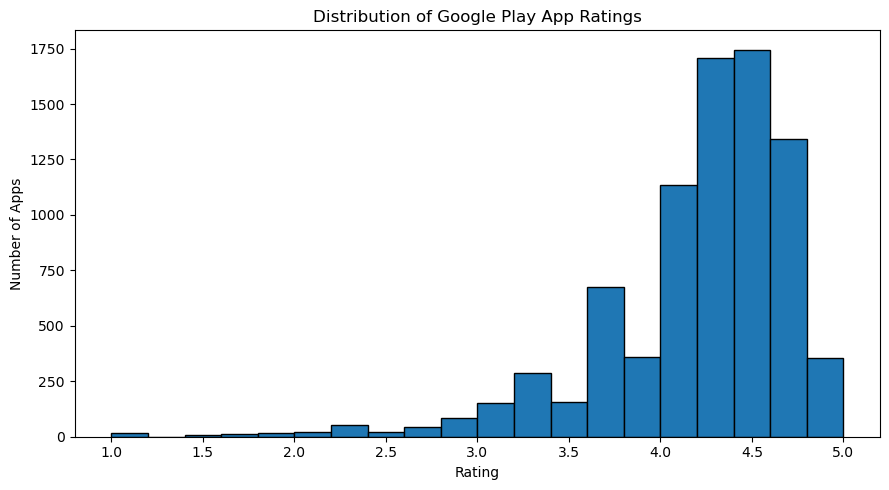

In [61]:
plt.figure(figsize=(9, 5))

plt.hist(rated_df["Rating"], bins=20, edgecolor="black")

plt.title("Distribution of Google Play App Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Apps")

plt.tight_layout()
plt.show()

#### Relationship Between Ratings and Market Engagement

To assess whether user satisfaction is associated with market success, ratings are compared with review activity and installation levels.

Because both reviews and installations are highly right-skewed, logarithmic transformations are used for visualisation and correlation analysis. This prevents a small number of extremely popular apps from dominating the observed relationships.

In [63]:
rated_df["Log_Reviews"] = np.log1p(rated_df["Reviews"])
rated_df["Log_Installs"] = np.log1p(rated_df["Installs"])

correlations = rated_df[
    ["Rating", "Log_Reviews", "Log_Installs"]
].corr()

display(correlations)

,Rating,Log_Reviews,Log_Installs
Rating,1.000000,0.182761,0.084752
Log_Reviews,0.182761,1.000000,0.952116
Log_Installs,0.084752,0.952116,1.000000


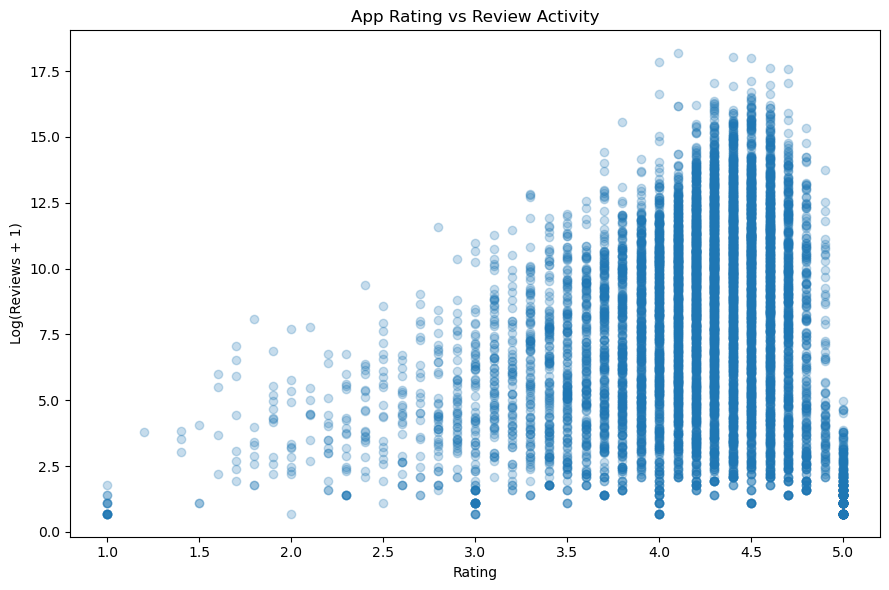

In [64]:
plt.figure(figsize=(9, 6))

plt.scatter(
    rated_df["Rating"],
    rated_df["Log_Reviews"],
    alpha=0.25
)

plt.title("App Rating vs Review Activity")
plt.xlabel("Rating")
plt.ylabel("Log(Reviews + 1)")

plt.tight_layout()
plt.show()

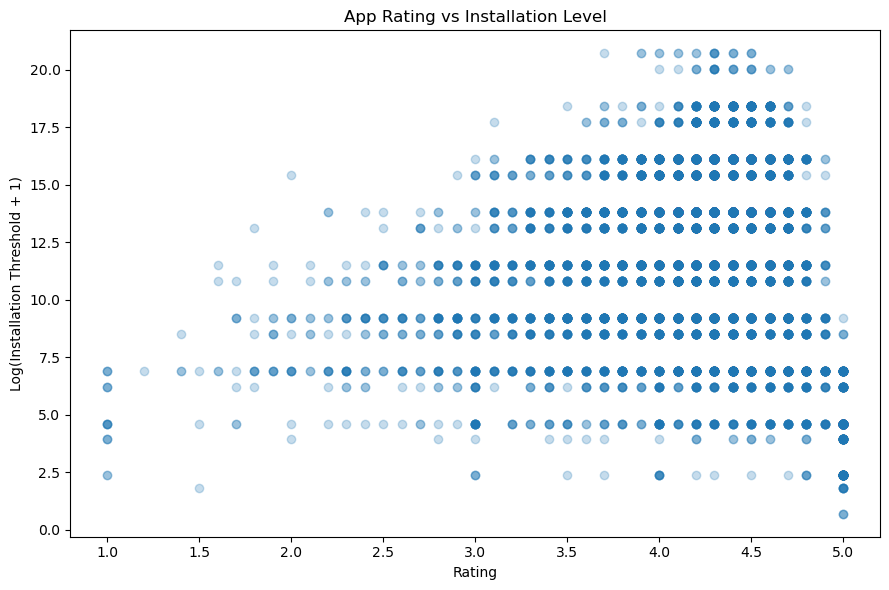

In [65]:
plt.figure(figsize=(9, 6))

plt.scatter(
    rated_df["Rating"],
    rated_df["Log_Installs"],
    alpha=0.25
)

plt.title("App Rating vs Installation Level")
plt.xlabel("Rating")
plt.ylabel("Log(Installation Threshold + 1)")

plt.tight_layout()
plt.show()

In [66]:
rating_bins = [0, 3, 3.5, 4, 4.5, 5]
rating_labels = [
    "≤3.0",
    "3.1–3.5",
    "3.6–4.0",
    "4.1–4.5",
    "4.6–5.0"
]

rated_df["Rating_Band"] = pd.cut(
    rated_df["Rating"],
    bins=rating_bins,
    labels=rating_labels,
    include_lowest=True
)

rating_performance = (
    rated_df.groupby("Rating_Band", observed=True)
    .agg(
        App_Count=("App", "count"),
        Median_Reviews=("Reviews", "median"),
        Median_Installs=("Installs", "median")
    )
)

display(rating_performance)

,App_Count,Median_Reviews,Median_Installs
Rating_Band,,,
≤3.0,359,54.0,5000.0
3.1–3.5,514,347.5,50000.0
3.6–4.0,1549,1420.0,100000.0
4.1–4.5,4075,12322.0,1000000.0
4.6–5.0,1699,1150.0,50000.0


#### Insight: High Ratings Alone Do Not Explain Market Adoption

App ratings show only a weak positive relationship with market engagement. Rating has a correlation of approximately 0.20 with log-transformed review activity and approximately 0.17 with log-transformed installation levels.

In contrast, review activity and installation levels are very strongly associated, with a correlation of approximately 0.95.

The rating-band comparison provides further evidence that stronger ratings are generally associated with higher engagement, but substantial variation remains within each rating range. Highly rated apps can still have relatively limited adoption, while some widely adopted apps do not have exceptional ratings.

This suggests that user satisfaction and market reach capture different dimensions of app performance. Ratings provide evidence of how existing users evaluate an app, whereas review volume and installations more directly reflect the scale of its audience.

### 3.3 Free versus Paid App Performance

The Google Play marketplace contains both free and paid applications, representing different monetisation strategies.

This section examines whether free and paid apps differ in market presence, user adoption, engagement, and ratings. The objective is to determine whether charging an upfront price is associated with materially different app-performance patterns.

In [69]:
type_summary = (
    df.groupby("Type")
    .agg(
        App_Count=("App", "count"),
        Median_Installs=("Installs", "median"),
        Median_Reviews=("Reviews", "median"),
        Median_Rating=("Rating", "median"),
        Mean_Rating=("Rating", "mean")
    )
)

type_summary["Market_Share_%"] = (
    type_summary["App_Count"] / len(df) * 100
).round(2)

type_summary["Mean_Rating"] = type_summary["Mean_Rating"].round(2)

display(type_summary)

,App_Count,Median_Installs,Median_Reviews,Median_Rating,Mean_Rating,Market_Share_%
Type,,,,,,
Free,8904,100000.0,1379.5,4.3,4.17,92.18
Paid,754,1000.0,88.5,4.4,4.26,7.81


<Figure size 700x500 with 0 Axes>

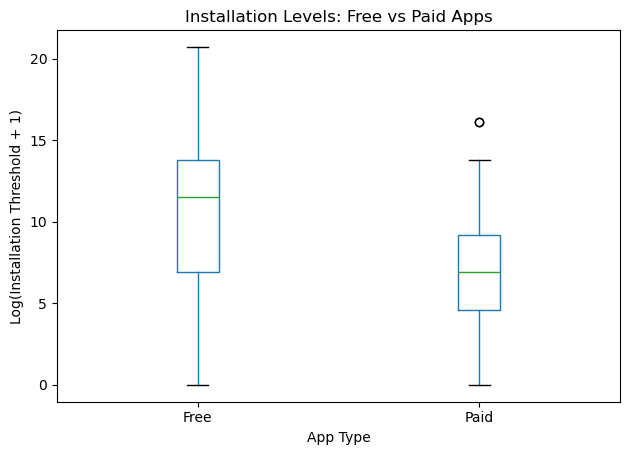

In [166]:
plt.figure(figsize=(7, 5))

df.boxplot(
    column="Log_Installs",
    by="Type",
    grid=False
)

plt.suptitle("")
plt.title("Installation Levels: Free vs Paid Apps")
plt.xlabel("App Type")
plt.ylabel("Log(Installation Threshold + 1)")

plt.tight_layout()
plt.show()

#### Insight: Free Apps Achieve Far Greater Reach Despite Slightly Lower Ratings

Free apps dominate the marketplace, accounting for 92.18% of the analysed apps compared with 7.81% for paid apps.

The difference in adoption is substantial. Free apps have a median installation threshold of 100,000, compared with only 1,000 for paid apps — a 100-fold difference. Median review activity also differs sharply, with 1,379.5 reviews for free apps compared with 88.5 for paid apps.

Paid apps nevertheless receive slightly stronger user evaluations, with a median rating of 4.4 compared with 4.3 for free apps and a mean rating of 4.26 compared with 4.17.

These patterns suggest a trade-off between reach and user evaluation: free apps achieve substantially broader adoption and engagement, while paid apps show only a modest ratings advantage. Upfront pricing therefore appears associated with a considerably smaller reachable audience in this marketplace.

### 3.4 Pricing and Monetisation

The substantial adoption gap between free and paid apps raises a further question: among apps that charge an upfront price, how does pricing relate to user adoption?

This section examines the paid-app market separately to identify its price structure, extreme pricing strategies, and the relationship between price and installation levels.

In [73]:
paid_df = df[df["Price"] > 0].copy()

print("Paid apps:", len(paid_df))
print("Median price: $", round(paid_df["Price"].median(), 2))
print("Mean price: $", round(paid_df["Price"].mean(), 2))

display(
    paid_df["Price"].describe(
        percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
    )
)

Paid apps: 754
Median price: $ 2.99
Mean price: $ 14.06


count    754.000000
mean      14.055902
std       58.821000
min        0.990000
25%        1.490000
50%        2.990000
75%        4.990000
90%        9.990000
95%       24.990000
99%      399.990000
max      400.000000
Name: Price, dtype: float64

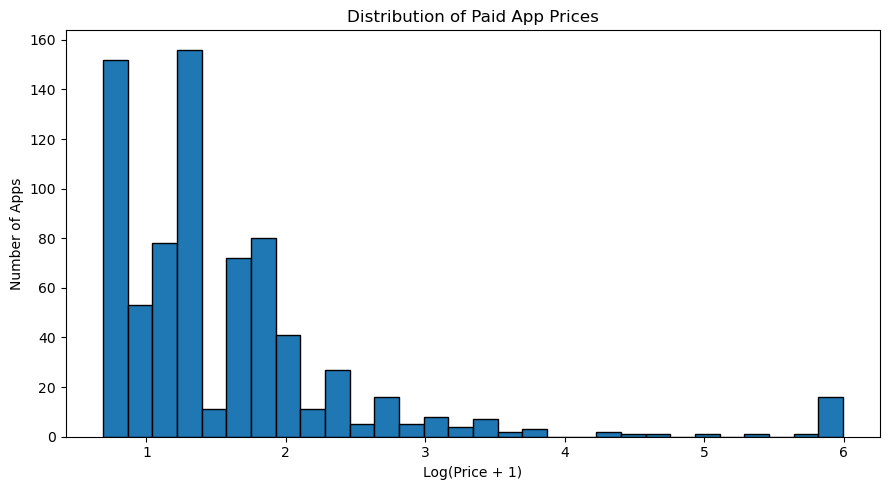

In [74]:
paid_df["Log_Price"] = np.log1p(paid_df["Price"])

plt.figure(figsize=(9, 5))

plt.hist(paid_df["Log_Price"], bins=30, edgecolor="black")

plt.title("Distribution of Paid App Prices")
plt.xlabel("Log(Price + 1)")
plt.ylabel("Number of Apps")

plt.tight_layout()
plt.show()

,Log_Price,Log_Installs
Log_Price,1.000000,0.016173
Log_Installs,0.016173,1.000000


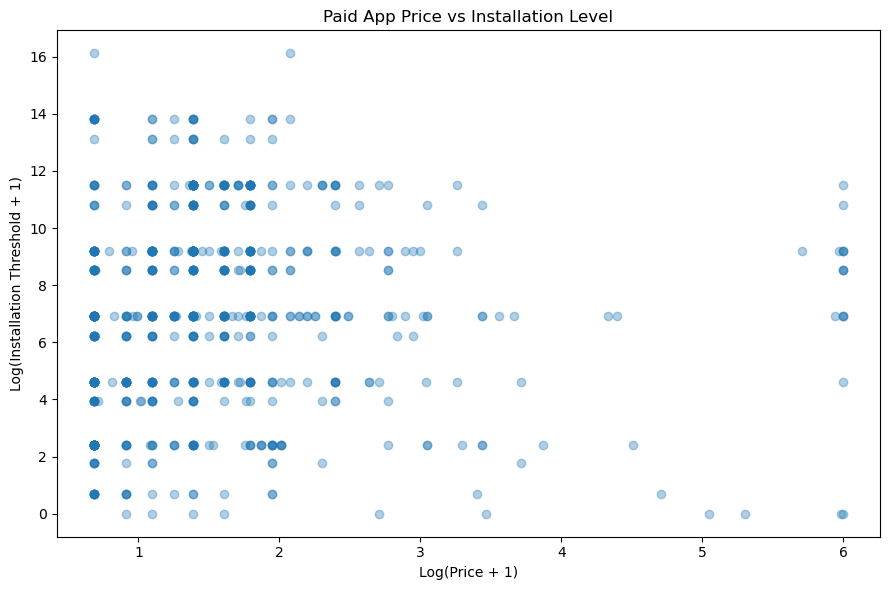

In [75]:
price_adoption_corr = paid_df[
    ["Log_Price", "Log_Installs"]
].corr()

display(price_adoption_corr)

plt.figure(figsize=(9, 6))

plt.scatter(
    paid_df["Log_Price"],
    paid_df["Log_Installs"],
    alpha=0.35
)

plt.title("Paid App Price vs Installation Level")
plt.xlabel("Log(Price + 1)")
plt.ylabel("Log(Installation Threshold + 1)")

plt.tight_layout()
plt.show()

#### Insight: Paid Apps Are Concentrated at Low Prices, with a Small Extreme-Pricing Segment

The paid-app market is strongly concentrated at relatively low price points. The median paid-app price is $2.99, and approximately three quarters of paid apps are priced at or below $4.99.

However, the price distribution contains a pronounced upper tail, with a small number of apps priced close to $400. These extreme values substantially increase the mean price relative to the median and represent a distinct pricing strategy rather than the typical paid-app market.

The relationship between price and installation level is weakly negative, indicating that higher-priced apps tend to have somewhat lower adoption, but price alone does not strongly explain market reach.

Combined with the earlier free-versus-paid comparison, the evidence suggests that the largest adoption difference occurs between free and paid access itself, while price variation among paid apps has a much weaker relationship with adoption.

### 3.5 App Characteristics and Performance

Beyond category, ratings, and monetisation strategy, app-level characteristics may also be associated with market performance.

This section examines whether reported app size and update recency show meaningful relationships with user adoption and ratings.

In [78]:
size_df = df[df["Size_MB"].notna()].copy()

size_correlations = size_df[
    ["Size_MB", "Rating", "Log_Installs"]
].corr()

display(size_correlations)

,Size_MB,Rating,Log_Installs
Size_MB,1.000000,0.062958,0.299785
Rating,0.062958,1.000000,0.059542
Log_Installs,0.299785,0.059542,1.000000


In [79]:
size_df["Size_Band"] = pd.cut(
    size_df["Size_MB"],
    bins=[0, 10, 25, 50, 100, np.inf],
    labels=[
        "≤10 MB",
        "10–25 MB",
        "25–50 MB",
        "50–100 MB",
        ">100 MB"
    ]
)

size_performance = (
    size_df.groupby("Size_Band", observed=True)
    .agg(
        App_Count=("App", "count"),
        Median_Installs=("Installs", "median"),
        Median_Rating=("Rating", "median"),
        Median_Reviews=("Reviews", "median")
    )
)

display(size_performance)

,App_Count,Median_Installs,Median_Rating,Median_Reviews
Size_Band,,,,
≤10 MB,3930,10000.0,4.2,119.0
10–25 MB,2101,50000.0,4.3,740.0
25–50 MB,1524,100000.0,4.3,2364.0
50–100 MB,876,1000000.0,4.3,24102.5


#### Insight: App Size Is Associated with Reach, but Not with Better Ratings

Reported app size shows virtually no relationship with user ratings, with a correlation of approximately 0.06. Median ratings also remain stable at around 4.2–4.3 across size groups.

A different pattern appears for market reach. App size has a modest positive relationship with installation level (approximately 0.30), and median installations increase from 10,000 among apps up to 10 MB to 100,000 among apps in the 25–100 MB range.

Review activity also increases substantially across the size groups, indicating that larger apps in this dataset tend to have larger observed user bases.

However, this relationship should not be interpreted as evidence that increasing app size improves adoption. App size may reflect underlying differences in app category, functionality, or content complexity. The result therefore indicates an association with market reach rather than a direct performance effect.

#### Update Recency and Performance

App maintenance may also be associated with user engagement and satisfaction. Update dates are examined to determine whether more recently updated apps tend to show different ratings or adoption levels.

In [83]:
# Use the latest update date in the dataset as the reference point
reference_date = df["Last Updated"].max()

df["Days_Since_Update"] = (
    reference_date - df["Last Updated"]
).dt.days

print("Reference date:", reference_date)
print("Median days since update:", df["Days_Since_Update"].median())

update_correlations = df[
    ["Days_Since_Update", "Rating", "Log_Installs", "Log_Reviews"]
].corr()

display(update_correlations)

Reference date: 2018-08-08 00:00:00
Median days since update: 96.0


,Days_Since_Update,Rating,Log_Installs,Log_Reviews
Days_Since_Update,1.000000,-0.130126,-0.183446,-0.191998
Rating,-0.130126,1.000000,0.084752,0.182761
Log_Installs,-0.183446,0.084752,1.000000,0.958784
Log_Reviews,-0.191998,0.182761,0.958784,1.000000


In [84]:
df["Update_Recency"] = pd.cut(
    df["Days_Since_Update"],
    bins=[-1, 90, 180, 365, 730, np.inf],
    labels=[
        "≤3 months",
        "3–6 months",
        "6–12 months",
        "1–2 years",
        ">2 years"
    ]
)

update_performance = (
    df.groupby("Update_Recency", observed=True)
    .agg(
        App_Count=("App", "count"),
        Median_Rating=("Rating", "median"),
        Median_Installs=("Installs", "median"),
        Median_Reviews=("Reviews", "median")
    )
)

display(update_performance)

,App_Count,Median_Rating,Median_Installs,Median_Reviews
Update_Recency,,,,
≤3 months,4765,4.3,500000.0,8600.0
3–6 months,1158,4.3,10000.0,198.0
6–12 months,1320,4.2,10000.0,170.5
1–2 years,1205,4.2,10000.0,119.0
>2 years,1211,4.2,10000.0,223.0


#### Insight: Recently Updated Apps Show Substantially Stronger Market Engagement

App update recency is negatively associated with both installation levels and review activity. As the time since an app's last update increases, observed market engagement generally declines.

Apps updated within the previous three months have a median installation threshold of 500,000 and a median of 8,600 reviews. In comparison, apps last updated one to two years earlier have a median installation threshold of only 10,000 and 119 reviews.

Ratings vary much less, with recently updated apps showing a median rating of 4.3 compared with approximately 4.2 among older apps.

The correlations between days since update and installation level (-0.18), review activity (-0.19), and rating (-0.13) are modest, indicating that update recency alone does not explain app performance. However, the grouped results show that recently maintained apps are associated with substantially larger observed user bases.

This should not be interpreted as evidence that frequent updates directly cause higher adoption. Popular apps may also receive more frequent development and maintenance, while category, app maturity, and publisher resources may influence both update frequency and market reach.

### 3.6 Audience Characteristics

Apps target different audience groups through their content-rating classifications. This section examines whether audience targeting is associated with differences in market adoption, engagement, and user ratings.

In [87]:
content_performance = (
    df.groupby("Content Rating")
    .agg(
        App_Count=("App", "count"),
        Median_Installs=("Installs", "median"),
        Median_Reviews=("Reviews", "median"),
        Median_Rating=("Rating", "median")
    )
    .sort_values("App_Count", ascending=False)
)

content_performance["Market_Share_%"] = (
    content_performance["App_Count"] / len(df) * 100
).round(2)

display(content_performance)

,App_Count,Median_Installs,Median_Reviews,Median_Rating,Market_Share_%
Content Rating,,,,,
Everyone,7903,50000.0,576.0,4.3,81.82
Teen,1036,500000.0,10144.0,4.3,10.73
Mature 17+,393,500000.0,3414.0,4.2,4.07
Everyone 10+,322,1000000.0,19023.0,4.3,3.33
Adults only 18+,3,500000.0,24005.0,4.5,0.03
Unrated,2,25250.0,593.5,4.1,0.02


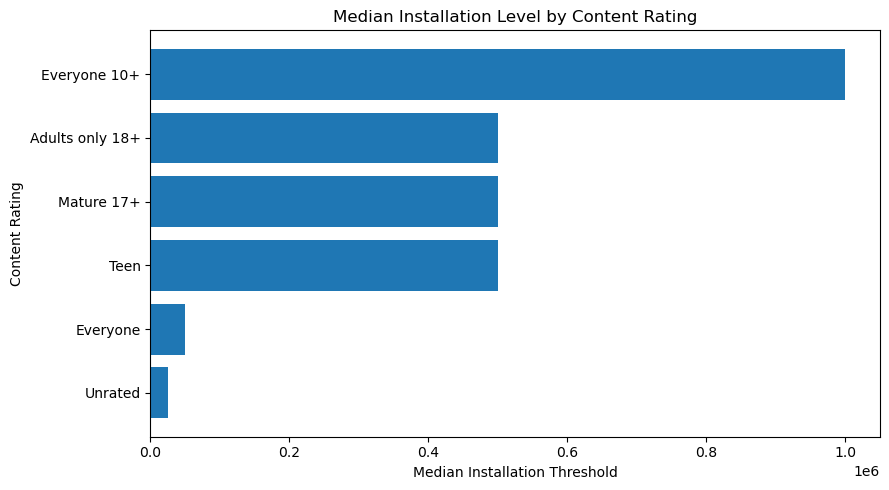

In [88]:
plt.figure(figsize=(9, 5))

content_plot = (
    content_performance["Median_Installs"]
    .sort_values(ascending=True)
)

plt.barh(content_plot.index, content_plot.values)

plt.title("Median Installation Level by Content Rating")
plt.xlabel("Median Installation Threshold")
plt.ylabel("Content Rating")

plt.tight_layout()
plt.show()

#### Insight: Broadest Market Supply Does Not Correspond to Highest Typical Adoption

Apps rated **Everyone** dominate the dataset, accounting for 81.82% of all apps. However, their median installation threshold is only 50,000, substantially below several more narrowly targeted content-rating groups.

Apps rated **Teen** and **Mature 17+** each have median installation thresholds of 500,000, while **Everyone 10+** apps have the highest median installation threshold at 1 million. Review activity follows a similar pattern, with Everyone 10+ and Teen apps showing substantially higher median review counts than the much larger Everyone segment.

Median ratings remain relatively stable across the major content-rating groups, ranging from approximately 4.2 to 4.3. This suggests that the differences are more pronounced in market reach and engagement than in average user evaluation.

The Adults only 18+ and Unrated groups contain only three and two apps respectively and are therefore too small to support reliable comparisons.

These results indicate an association between audience classification and observed market reach, but they should not be interpreted as evidence that targeting a particular age group causes greater adoption. Differences in app category, popularity, functionality, and other characteristics may contribute to the observed pattern.

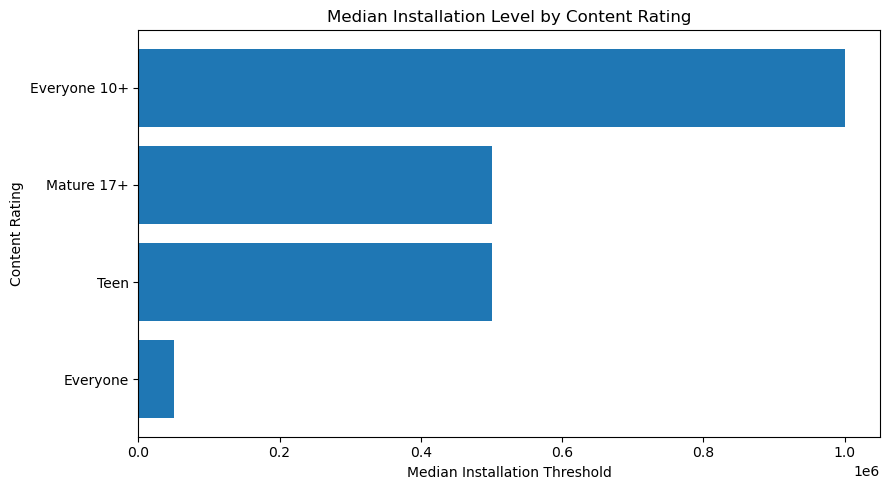

In [90]:
# Exclude very small groups from visual comparison
content_plot = (
    content_performance[
        content_performance["App_Count"] >= 30
    ]["Median_Installs"]
    .sort_values(ascending=True)
)

plt.figure(figsize=(9, 5))
plt.barh(content_plot.index, content_plot.values)

plt.title("Median Installation Level by Content Rating")
plt.xlabel("Median Installation Threshold")
plt.ylabel("Content Rating")

plt.tight_layout()
plt.show()

## 4. Statistical Analysis

The exploratory analysis identified several differences in adoption and engagement across app characteristics. However, descriptive patterns alone do not establish whether these differences are statistically meaningful.

This section applies statistical tests and modelling techniques to evaluate selected relationships identified during EDA, while accounting for the highly skewed nature of installation and review data.

The analysis focuses on:

- whether free and paid apps differ significantly in adoption;
- whether app ratings are associated with installation and review activity;
- whether update recency is associated with app performance;
- which app characteristics remain associated with adoption when considered jointly.

### 4.1 Free vs Paid App Adoption

EDA showed a substantial difference in typical installation levels between free and paid apps. A statistical comparison is performed to determine whether the observed difference is supported beyond the descriptive sample statistics.

Because installation levels are strongly skewed, the comparison uses the log-transformed installation measure.

In [93]:
from scipy import stats

free_installs = df.loc[df["Type"] == "Free", "Log_Installs"].dropna()
paid_installs = df.loc[df["Type"] == "Paid", "Log_Installs"].dropna()

print("Free apps:", len(free_installs))
print("Paid apps:", len(paid_installs))

print("\nMedian log installs:")
print("Free:", round(free_installs.median(), 3))
print("Paid:", round(paid_installs.median(), 3))

# Mann–Whitney U test
u_stat, p_value = stats.mannwhitneyu(
    free_installs,
    paid_installs,
    alternative="two-sided"
)

print("\nMann–Whitney U statistic:", round(u_stat, 2))
print("p-value:", p_value)

# Effect size: rank-biserial correlation
n1 = len(free_installs)
n2 = len(paid_installs)

rank_biserial = (2 * u_stat) / (n1 * n2) - 1

print("Rank-biserial effect size:", round(rank_biserial, 3))

Free apps: 8904
Paid apps: 754

Median log installs:
Free: 11.513
Paid: 6.909

Mann–Whitney U statistic: 5031685.5
p-value: 6.689177758645997e-116
Rank-biserial effect size: 0.499


#### Statistical Finding: Free Apps Show Substantially Greater Adoption

The Mann–Whitney U test identified a statistically significant difference in installation levels between free and paid apps (U = 5,031,685.5, p < 0.001).

Free apps had a median log installation level of 11.513 compared with 6.909 for paid apps. The rank-biserial correlation of 0.499 indicates a substantial difference between the two groups, showing that the result is not simply a consequence of the large sample size.

This supports the earlier exploratory finding that free apps tend to achieve substantially greater market reach than paid apps. However, the result represents an association between pricing model and adoption rather than evidence that making an app free directly causes higher installations.

### 4.2 Ratings and User Engagement

Exploratory analysis suggested that app ratings have only a limited relationship with installation levels, while review activity may show a somewhat stronger association.

Spearman rank correlation is used to evaluate these relationships because installation and review measures are highly skewed and the relationships need not be linear.

In [96]:
rated_stats = df[
    ["Rating", "Installs", "Reviews"]
].dropna()

rating_installs_rho, rating_installs_p = stats.spearmanr(
    rated_stats["Rating"],
    rated_stats["Installs"]
)

rating_reviews_rho, rating_reviews_p = stats.spearmanr(
    rated_stats["Rating"],
    rated_stats["Reviews"]
)

print("Rating vs Installs")
print("Spearman rho:", round(rating_installs_rho, 3))
print("p-value:", rating_installs_p)

print("\nRating vs Reviews")
print("Spearman rho:", round(rating_reviews_rho, 3))
print("p-value:", rating_reviews_p)

Rating vs Installs
Spearman rho: 0.027
p-value: 0.013849656692897056

Rating vs Reviews
Spearman rho: 0.12
p-value: 1.636818779609663e-27


#### Statistical Finding: Ratings Have Limited Association with Engagement

App rating showed a statistically significant but practically negligible positive association with installation levels (Spearman's ρ = 0.027, p = 0.014). Despite statistical significance, the effect size is sufficiently small to indicate little meaningful relationship between rating and market adoption.

The association between rating and review activity was somewhat stronger (ρ = 0.120, p < 0.001), but remained weak.

These results suggest that higher-rated apps are not necessarily the most widely adopted. User ratings therefore appear to provide relatively limited information about market reach when considered independently.

### 4.3 Update Recency and App Performance

Exploratory analysis indicated that more recently updated apps tended to show higher installation and review activity. Spearman rank correlation is used to evaluate whether update recency is systematically associated with adoption, engagement, and user ratings.

In [99]:
recency_stats = df[
    ["Days_Since_Update", "Installs", "Reviews", "Rating"]
].dropna()

for variable in ["Installs", "Reviews", "Rating"]:
    rho, p = stats.spearmanr(
        recency_stats["Days_Since_Update"],
        recency_stats[variable]
    )
    
    print(f"Days Since Update vs {variable}")
    print("Spearman rho:", round(rho, 3))
    print("p-value:", p)
    print()

Days Since Update vs Installs
Spearman rho: -0.369
p-value: 3.525572112982293e-263

Days Since Update vs Reviews
Spearman rho: -0.374
p-value: 3.271929081291962e-271

Days Since Update vs Rating
Spearman rho: -0.182
p-value: 4.03462201263248e-62



#### Statistical Finding: Update Recency Is Associated with Stronger App Performance

Update recency showed statistically significant negative associations with all three performance measures. Days since the most recent update was moderately negatively associated with installations (Spearman's ρ = -0.369, p < 0.001) and review activity (ρ = -0.374, p < 0.001), while its relationship with app rating was weaker (ρ = -0.182, p < 0.001).

Because larger values of `Days_Since_Update` represent longer periods since an app was updated, these results indicate that more recently updated apps tend to have greater adoption and user engagement.

The relationship is substantially stronger for installations and reviews than for ratings, suggesting that update recency is more closely associated with market activity than with users' average evaluation of an app.

These associations should not be interpreted causally. Frequently updated apps may differ systematically from older apps in popularity, developer resources, category, functionality, or other characteristics that also influence market performance.

### 4.4 Multivariable Analysis of App Adoption

The preceding analyses examined app characteristics individually. However, relationships observed in isolation may partly reflect differences in other app attributes.

A multivariable regression model is therefore used to examine how rating, pricing model, app size, update recency, and content rating are jointly associated with installation levels.

The logarithm of installations is used as the outcome variable to reduce the influence of the highly skewed installation distribution. The model is intended to identify conditional associations rather than establish causal effects.

In [102]:
import statsmodels.formula.api as smf

model_df = df[
    [
        "Log_Installs",
        "Rating",
        "Type",
        "Size_MB",
        "Days_Since_Update",
        "Content Rating"
    ]
].dropna().copy()

# Rename column for formula compatibility
model_df = model_df.rename(
    columns={"Content Rating": "Content_Rating"}
)

print("Observations used:", len(model_df))

adoption_model = smf.ols(
    formula="""
        Log_Installs ~ Rating
        + C(Type)
        + Size_MB
        + Days_Since_Update
        + C(Content_Rating)
    """,
    data=model_df
).fit()

print(adoption_model.summary())

Observations used: 7026
                            OLS Regression Results                            
Dep. Variable:           Log_Installs   R-squared:                       0.171
Model:                            OLS   Adj. R-squared:                  0.169
Method:                 Least Squares   F-statistic:                     160.3
Date:                Mon, 03 Aug 2026   Prob (F-statistic):          5.82e-277
Time:                        17:19:14   Log-Likelihood:                -18277.
No. Observations:                7026   AIC:                         3.657e+04
Df Residuals:                    7016   BIC:                         3.664e+04
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                                        coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------

#### Model Diagnostics and Standardisation

The initial regression identified a high condition number, indicating potential numerical instability caused by predictors operating on substantially different scales.

To improve numerical conditioning and make continuous coefficients more directly comparable, the continuous predictors are standardised before refitting the model. Categorical variables remain unchanged.

In [104]:
from sklearn.preprocessing import StandardScaler

model_scaled = model_df.copy()

continuous_vars = [
    "Rating",
    "Size_MB",
    "Days_Since_Update"
]

scaler = StandardScaler()

model_scaled[continuous_vars] = scaler.fit_transform(
    model_scaled[continuous_vars]
)

adoption_model_scaled = smf.ols(
    formula="""
        Log_Installs ~ Rating
        + C(Type)
        + Size_MB
        + Days_Since_Update
        + C(Content_Rating)
    """,
    data=model_scaled
).fit()

print(adoption_model_scaled.summary())

                            OLS Regression Results                            
Dep. Variable:           Log_Installs   R-squared:                       0.171
Model:                            OLS   Adj. R-squared:                  0.169
Method:                 Least Squares   F-statistic:                     160.3
Date:                Mon, 03 Aug 2026   Prob (F-statistic):          5.82e-277
Time:                        17:19:14   Log-Likelihood:                -18277.
No. Observations:                7026   AIC:                         3.657e+04
Df Residuals:                    7016   BIC:                         3.664e+04
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                                        coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
Interc

#### Multivariable Findings: Pricing Model, App Size and Update Recency Remain Associated with Adoption

The multivariable model was statistically significant overall (F = 160.3, p < 0.001) and explained approximately 17.1% of the variation in log installation levels (adjusted R² = 0.169). This indicates that the included app characteristics provide meaningful but limited explanatory power, with substantial variation in adoption remaining unexplained.

After accounting for the other variables in the model, paid apps remained strongly negatively associated with adoption (β = -3.257, p < 0.001). Among the standardised continuous predictors, app size showed the largest positive association with log installations (β = 0.895, p < 0.001), while greater time since the last update was negatively associated with adoption (β = -0.324, p < 0.001). Rating showed a smaller positive association (β = 0.141, p < 0.001).

Notably, none of the content-rating categories showed a statistically significant independent association with adoption after the other characteristics were considered. This contrasts with the descriptive differences observed during EDA and suggests that content rating itself provides limited additional explanatory information once pricing model, rating, app size and update recency are taken into account.

Standardising the continuous predictors substantially reduced the model's condition number while preserving the substantive results, improving numerical stability and allowing their relative associations to be compared more directly.

The model is explanatory rather than causal or predictive. Its relatively modest R² indicates that important determinants of app adoption are not captured by the available dataset.

## 5. Business Insights and Recommendations

The analysis identified several patterns relevant to app-market positioning, user adoption and product strategy. The recommendations below translate the strongest findings into practical implications while avoiding causal claims unsupported by the observational data.

### 5.1 Pricing Strategy and Market Reach

Free apps represented approximately 92% of the analysed market and showed substantially higher installation levels than paid apps. Median log installations were 11.513 for free apps compared with 6.909 for paid apps.

The difference was statistically significant (Mann–Whitney U = 5,031,685.5, p < 0.001) with a rank-biserial effect size of approximately 0.50, indicating a substantial difference in adoption between the two groups.

Paid status also remained strongly negatively associated with installation levels after accounting for rating, app size, update recency and content rating in the multivariable analysis.

**Recommendation:** Developers seeking broad market reach should carefully evaluate the adoption barrier created by upfront pricing. Where commercially appropriate, free-entry monetisation models may provide greater potential for user acquisition than requiring payment before installation.


### 5.2 App Maintenance and User Adoption

Update recency produced one of the clearest engagement patterns in the analysis. Days since the most recent update was negatively associated with both installations (Spearman ρ = -0.369) and reviews (ρ = -0.374), while a weaker negative association was also observed with ratings (ρ = -0.182). All three relationships were statistically significant.

The negative association between time since update and adoption also remained significant in the multivariable model after accounting for other app characteristics.

**Recommendation:** Regular maintenance should be treated as an important component of app-market strategy. Developers should monitor update cycles and investigate ageing applications whose engagement is declining. However, the observational data cannot establish that updating an app itself causes greater adoption.


### 5.3 Ratings Are a Weak Indicator of Market Reach

Higher-rated apps did not necessarily achieve substantially greater adoption. Rating had almost no monotonic relationship with installations (Spearman ρ = 0.027), although its relationship with review activity was somewhat stronger (ρ = 0.120).

Rating remained positively associated with installations in the multivariable model, but its standardised coefficient (β = 0.141) was considerably smaller than the associations observed for app size and pricing model.

**Recommendation:** App ratings should not be used in isolation as a measure of market success. Performance monitoring should combine user evaluation metrics with adoption and engagement measures such as installations and review activity.


### 5.4 App Characteristics and Market Positioning

App size showed a moderate positive relationship with installation levels (Pearson r ≈ 0.30) and remained positively associated with adoption in the multivariable analysis (standardised β = 0.895, p < 0.001).

This should not be interpreted as evidence that increasing app size improves adoption. Larger apps may represent different categories, functionality levels or product complexity that are themselves associated with market reach.

Content rating, meanwhile, provided little additional explanatory information after the other app characteristics were considered.

**Recommendation:** Product characteristics such as app size and audience classification should be interpreted within their broader market context rather than treated as independent levers for increasing adoption.


### 5.5 Overall Strategic Takeaway

The analysis suggests that market adoption is shaped more strongly by factors surrounding accessibility, product characteristics and maintenance than by user ratings alone.

Three findings stand out:

1. **Pricing model matters:** paid apps showed substantially lower adoption than free apps.
2. **Maintenance matters:** older updates were consistently associated with lower installation and review activity.
3. **Ratings are not equivalent to reach:** highly rated apps were not necessarily the most widely adopted.

For app developers and product teams, this suggests that acquisition strategy, continued product maintenance and broader engagement measures should be considered alongside traditional app-store ratings when evaluating market performance.

These findings describe associations within the available Google Play Store dataset and should not be interpreted as evidence of causal effects.

## 6. Conclusion and Limitations

### 6.1 Conclusion

This project examined the Google Play Store ecosystem to identify patterns associated with app adoption, user engagement and monetisation.

The analysis found substantial variation in market performance across app categories and business models. Free apps achieved considerably greater installation levels than paid apps, while recently updated apps tended to show stronger adoption and review activity. App ratings, despite being a prominent measure of user satisfaction, showed only a weak relationship with installation levels.

Multivariable analysis reinforced several of these findings. Paid status remained negatively associated with adoption after accounting for other app characteristics, while update recency and app size also showed meaningful associations with installation levels.

Overall, the results demonstrate that app-market performance cannot be understood through ratings alone. Pricing strategy, continued maintenance, product characteristics and engagement measures provide important additional context when evaluating an application's market position.


### 6.2 Limitations

Several limitations should be considered when interpreting the results:

- **Observational data:** The analysis identifies associations rather than causal relationships. For example, the results cannot establish that frequent updates directly increase installations.
- **Historical snapshot:** The dataset represents the Google Play Store at a particular point in time and may not reflect the current app marketplace.
- **Installation measurement:** Install counts are provided as thresholds (for example, 100,000+ or 1,000,000+) rather than exact values, limiting measurement precision.
- **Missing ratings:** Approximately 15% of unique apps had no available rating. These observations were retained where possible rather than artificially imputing user ratings.
- **Unobserved factors:** Variables such as advertising expenditure, brand recognition, app quality, in-app purchases and promotional activity are unavailable and may influence market performance.
- **Model interpretation:** The regression model explains only part of the variation in installation levels (R² ≈ 0.17), indicating that substantial determinants of adoption are not captured by the available variables.

These limitations mean that the findings should be interpreted as evidence of market patterns within the dataset rather than definitive explanations of app success.